In [1]:
#importing
import pandas as pd
import numpy as np
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_selection import chi2
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB, ComplementNB
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, accuracy_score, f1_score, recall_score
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
import seaborn as sns

In [2]:
#downloading needed nltk  resources
for resource in ["punkt", "punkt_tab", "stopwords", "wordnet"]:
    nltk.download(resource, quiet=True)

In [3]:
#loading data
data = pd.read_json("../data/research_abstracts.json")

In [4]:
#inspecting data
print(data.shape)
print(data.columns.tolist())
print(data.isnull().sum())
print(data["Label"].value_counts())
print("Duplicate abstracts:", data["Abstract"].duplicated().sum())

(1138, 3)
['DOI', 'Abstract', 'Label']
DOI         4
Abstract    0
Label       0
dtype: int64
Label
classical    900
ai           238
Name: count, dtype: int64
Duplicate abstracts: 13


----------
QUESTION 1.1


In [5]:
#preprocessing data
#dropping duplicates
data = data.drop_duplicates(subset="Abstract").reset_index(drop=True)
print(data.shape)

(1125, 3)


In [6]:
lemmatizer = WordNetLemmatizer()

#adding standard English stopwords plus words common to every abstract
stop_words = set(stopwords.words("english"))
stop_words.update(["paper", "study", "result", "results", "using", "use", "also", "show", "find",
                   "abstract", "article"])

#defining text cleaning function
def clean_text(text, min_len=3):
    #remove biolerplate specific to dataset
    text = re.sub(r"\[Formula: see text\]", " ", text)
    text = re.sub(r"Copyright\s*©.*", " ", text) #copyright notices
    text = re.sub(r"http\S+|www\.\S+", " ", text) #urls
    text = re.sub(r"(Background|Objectives?|Methods?|Results?(?: and Conclusions?)?|Conclusions?|Purpose|Findings)(?=[A-Z])",
    " ", text)  #headings stuck to next word

    #lowercase
    text = text.lower()

    #removing numbers and punctuation
    text = re.sub(r"[^a-z\s]", " ", text)

    #tokenise
    tokens = word_tokenize(text)

    #removing stopwords and short tokens then lemmatise
    tokens = [lemmatizer.lemmatize(t) for t in tokens]
    tokens = [t for t in tokens if t not in stop_words and len(t) >= min_len]

    #joining back into single string
    return " ".join(tokens)

In [7]:
#comapring before and after
data["clean"] = data["Abstract"].apply(clean_text)

print(data.loc[4, "Abstract"][:400])
print("---")
print(data.loc[4, "clean"][:400])

BackgroundGame theory is useful for identifying conditions under which individual stakeholders in a collective action problem interact in ways that are more cooperative and in the best interest of the collective. The literature applying game theory to healthcare markets predicts that when providers set prices for services autonomously and in a noncooperative fashion, the market will be susceptible
---
game theory useful identifying condition individual stakeholder collective action problem interact way cooperative best interest collective literature applying game theory healthcare market predicts provider set price service autonomously noncooperative fashion market susceptible ongoing price inflation compare traditional fee service pricing framework alternative framework involving modified doct


In [8]:
#check to show effect of the cleaning
data["raw_len"] = data["Abstract"].str.split().str.len()
data["clean_len"] = data["clean"].str.split().str.len()
print(data[["raw_len", "clean_len"]].describe())

           raw_len    clean_len
count  1125.000000  1125.000000
mean    171.594667   101.015111
std     103.924594    61.183427
min      16.000000     9.000000
25%     116.000000    68.000000
50%     152.000000    91.000000
75%     201.000000   118.000000
max    2075.000000  1264.000000


In [9]:
#further checking outliers (unusually high max value for raw_len and min 16 words)
print(data.sort_values("raw_len", ascending=False)[["Abstract", "Label", "raw_len"]].head(3))
print(data.sort_values("raw_len")[["Abstract", "Label", "raw_len"]].head(3))

                                               Abstract      Label  raw_len
1122  Francesca Gino, Erin L. Krupka, Roberto A. Web...  classical     2075
1124  The Encyclopedia Americana, 2002 edition, conc...  classical     1206
1106  Purpose- This paper employs the public debt eq...         ai      780
                                              Abstract      Label  raw_len
38   We review the prediction of inflation and the ...         ai       16
548  This article studies the usefulness of low ord...  classical       24
88   A technique developed for evaluating the marke...  classical       34


In [10]:
print(data.loc[1122, "Abstract"][:1500])
print(data.loc[1124, "Abstract"][:1500])

Francesca Gino, Erin L. Krupka, Roberto A. Weber Does the option for regulatory oversight change behavior? Although monitoring and regulation can be used to combat socially costly unethical conduct, their intended targets can often avoid regulation or hide their behavior. This surrenders at least part of the effectiveness of regulatory policies to firms' and individuals' decisions to voluntarily submit to regulation. The authors study individuals' decisions to avoid monitoring or regulation and thus enhance their ability to engage in unethical conduct. They conduct a laboratory experiment in which participants engage in a competitive task and can decide between having the opportunity to misreport their performance and having their performance verified by an external monitor. To study the effect of social factors on the willingness to be subject to monitoring, the authors vary whether participants make this decision simultaneously with others or sequentially, as well as whether the deci

In [11]:
#dropping both as neither are abstracts
data = data.drop(index=[1122, 1124]).reset_index(drop=True)
print(data.shape)

(1123, 6)


-----
Both records removed as outliers as one contained several concatenated abstracts from unrelated papers and the other was a biographical essay rather than an research abstract

-------
QUESTION 1.2

In [12]:
#feature extraction using tf-idf
tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1, 2), min_df=2)
X_tfidf = tfidf.fit_transform(data["clean"])
terms = np.array(tfidf.get_feature_names_out())
#finding 15 terms with highest aveage tf-idf score
for label in ["ai", "classical"]:
    mask = (data["Label"] == label).values
    mean_scores = X_tfidf[mask].mean(axis=0).A1
    top = terms[mean_scores.argsort()[::-1][:15]]
    print(label, ":", ", ".join(top))

print("TF-IDF matrix shape:", X_tfidf.shape)

ai : model, price, method, forecast, inflation, data, learning, rate, forecasting, network, stock, prediction, regression, machine, neural
classical : inflation, model, rate, price, forecast, policy, prediction, monetary, country, economic, expectation, growth, interest, time, data
TF-IDF matrix shape: (1123, 5000)


In [13]:
#converting labels to binary
y = (data["Label"] == "ai").astype(int)

#doing chi-square test to test association of term and a class
chi_scores, p_values = chi2(X_tfidf, y)

#indexes of top 20 high chi scores
top_idx = chi_scores.argsort()[::-1][:20]

for term, score in zip(terms[top_idx], chi_scores[top_idx]):
    print(f"{term:25s} {score:.2f}")

machine                   22.58
network                   22.38
neural                    21.66
neural network            21.01
machine learning          20.23
learning                  20.08
algorithm                 16.75
lstm                      12.89
svr                       12.62
ann                       12.09
gold                      11.40
quantile                  11.28
method                    10.60
artificial                9.89
forest                    9.56
sentiment                 9.22
random forest             8.76
bitcoin                   8.66
regression                7.67
tree                      7.57


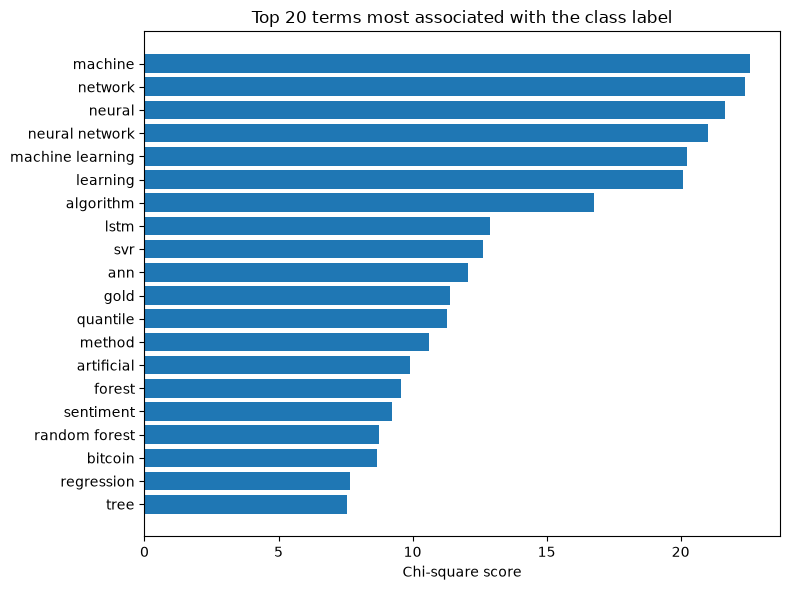

In [14]:
#visual showing top 20 chi-square terms
plt.figure(figsize=(8,6))
plt.barh(terms[top_idx][::-1], chi_scores[top_idx][::-1])
plt.xlabel("Chi-square score")
plt.title("Top 20 terms most associated with the class label")
plt.tight_layout()
plt.show()

----------
QUESTION 1.3

In [15]:
#splitting data into train and test split

#features (cleaned) and target (label)
X = data["clean"]
y = data["Label"]

#doing 80/20 split
X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=0.2, stratify=y, random_state=42)

print("Training set:", X_train.shape[0], "abstracts")
print("Test set:", X_test.shape[0], "abstracts")

Training set: 898 abstracts
Test set: 225 abstracts


In [16]:
#making dummy model that always predicts most common class, shows minimum accuracy any real model must beat
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)
print("Majority-class accuracy:", round(dummy.score(X_test, y_test), 3))

Majority-class accuracy: 0.791


In [17]:
#baseline model

#pipeline: tf-idf is fit on training only, model then trained on output
baseline = Pipeline([
    ("tfidf", TfidfVectorizer(max_features=5000, ngram_range=(1,2), min_df=2)),
    ("model", MultinomialNB())
])

baseline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('tfidf', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[<U9](2,)","['ai','classical']"
,"ngram_range ngram_range: tuple (min_n, max_n), default=(1, 1)The lower and upper boundary of the range of n-values for differentn-grams to be extracted. All values of n such that min_n <= n <= max_nwill be used. For example an ``ngram_range`` of ``(1, 1)`` means onlyunigrams, ``(1, 2)`` means unigrams and bigrams, and ``(2, 2)`` meansonly bigrams.Only applies if ``analyzer`` is not callable.","(1, ...)"
,"min_df min_df: float or int, default=1When building the vocabulary ignore terms that have a documentfrequency strictly lower than the given threshold. This value is alsocalled cut-off in the literature.If float in range of [0.0, 1.0], the parameter represents a proportionof documents, integer absolute counts.This parameter is ignored if vocabulary is not None.",2
,"max_features max_features: int, default=NoneIf not None, build a vocabulary that only consider the top`max_features` ordered by term frequency across the corpus.Otherwise, all features are used.This parameter is ignored if vocabulary is not None.",5000
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'


TRAINING SET
              precision    recall  f1-score   support

          ai       1.00      0.48      0.65       188
   classical       0.88      1.00      0.94       710

    accuracy                           0.89       898
   macro avg       0.94      0.74      0.79       898
weighted avg       0.90      0.89      0.88       898

TEST SET
              precision    recall  f1-score   support

          ai       1.00      0.23      0.38        47
   classical       0.83      1.00      0.91       178

    accuracy                           0.84       225
   macro avg       0.92      0.62      0.64       225
weighted avg       0.87      0.84      0.80       225



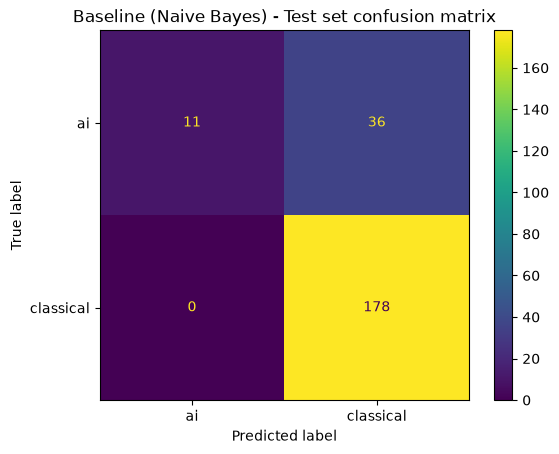

In [18]:
#performance report

#predictions on both sets
train_pred = baseline.predict(X_train)
test_pred = baseline.predict(X_test)

#checking training performance to see how well model learned data
print("TRAINING SET")
print(classification_report(y_train, train_pred))

#test performance
print("TEST SET")
print(classification_report(y_test, test_pred))

#confusion matrix for test set
ConfusionMatrixDisplay.from_predictions(y_test, test_pred)
plt.title("Baseline (Naive Bayes) - Test set confusion matrix")
plt.show()

In [19]:
#cross validation for more reliable estimate
cv_scores = cross_val_score(baseline, X_train, y_train, cv=5, scoring="f1_macro")
print("CV macro F1 scores:", cv_scores.round(3))
print("Mean CV macro F1:", round(cv_scores.mean(), 3))

CV macro F1 scores: [0.606 0.626 0.645 0.631 0.611]
Mean CV macro F1: 0.624


------
1.3 Performance report and discussion

A Multinomial Naive Bayes classifier was used as the baseline, with TF-IDF features (unigrams and bigrams) fitted on the training data only through a pipeline. The data was split 80/20 into 898 training and 225 test abstracts, stratified to keep the 79/21 classical-to-AI ratio.

*Learning and generalisation:* The model reached 0.89 accuracy and 0.79 macro F1 on the training set, but only 0.84 accuracy and 0.64 macro F1 on the test set. Test accuracy is only slightly above the 0.791 achieved by always predicting "classical", so accuracy alone is misleading here. The main weakness is the AI class: recall was 0.48 on the training set and 0.23 on the test set, with only 11 of 47 AI abstracts identified. AI precision was 1.00, so the model only predicted AI when very certain, while all 178 classical abstracts were classified correctly. Five-fold cross-validation gave a mean macro F1 of 0.624 (range 0.606-0.645), close to the test score, which shows the results are stable.

*Discussion:* The baseline is biased towards the majority class. This is likely because Naive Bayes uses class priors, which favour "classical" under a 79/21 imbalance, and because both classes share most of their vocabulary, with only a small set of method terms (e.g. "neural network", "LSTM", "SVR") separating them. Some label noise, such as a physics abstract on cosmological inflation labelled as AI, also contributes. Improving AI recall is therefore the main goal for the next question.

--------------
QUESTION 2
---

----------
QUESTION 2.1

In [20]:
#training ML models
models = {
    "Naive Bayes (baseline)": MultinomialNB(),
    "Logistic Regression": LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42),
    "Linear SVM": LinearSVC(class_weight="balanced", random_state=42),
    "Complement NB": ComplementNB(),
    "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42, n_jobs=-1)
}

results = []
fitted_models = {}

for name, model in models.items():
    #same tf-idf settings as baseline for fair comparison
    pipe = Pipeline([
        ("tfidf", TfidfVectorizer(max_features=5000, ngram_range=(1, 2), min_df=2)),
        ("model", model)
    ])

    pipe.fit(X_train, y_train)
    fitted_models[name] = pipe

    train_pred = pipe.predict(X_train)
    test_pred = pipe.predict(X_test)

    #5fold cross-validation macro f1
    cv = cross_val_score(pipe, X_train, y_train, cv=5, scoring="f1_macro")

    #storing metrics for this model
    results.append({
    "Model": name,
    "Train macro F1": f1_score(y_train, train_pred, average="macro"),
    "Test macro F1": f1_score(y_test, test_pred, average="macro"),
    "Test accuracy": accuracy_score(y_test, test_pred),
    "Test AI recall": recall_score(y_test, test_pred, pos_label="ai"),
    "CV macro F1": cv.mean()
    })

#comparison table sorted by test macro f1
results_df = pd.DataFrame(results).sort_values("Test macro F1", ascending=False)
print(results_df.round(3).to_string(index=False))

                 Model  Train macro F1  Test macro F1  Test accuracy  Test AI recall  CV macro F1
         Random Forest           1.000          0.883          0.924           0.787        0.849
            Linear SVM           0.998          0.861          0.911           0.745        0.832
   Logistic Regression           0.967          0.849          0.898           0.787        0.820
         Complement NB           0.922          0.830          0.898           0.638        0.809
Naive Bayes (baseline)           0.791          0.644          0.840           0.234        0.624


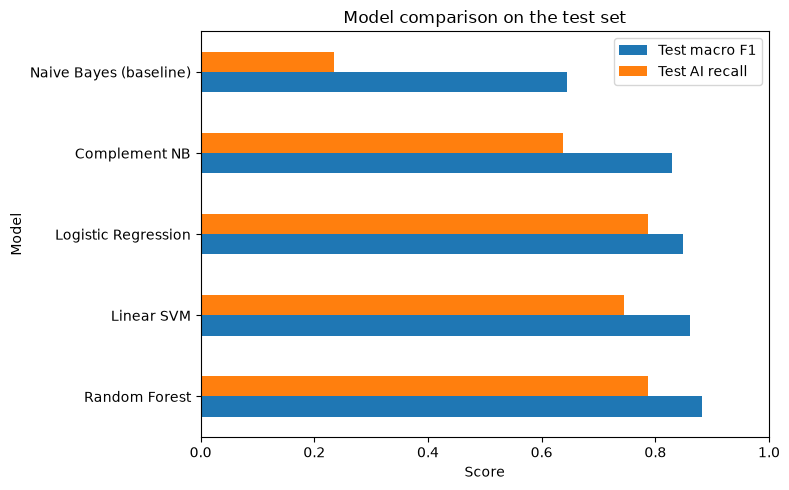

In [21]:
#bar chart to comapre test macro f1 and ai recall for each model
results_df.set_index("Model")[["Test macro F1", "Test AI recall"]].plot(kind="barh", figsize=(8, 5))
plt.title("Model comparison on the test set")
plt.xlabel("Score")
plt.xlim(0, 1)
plt.tight_layout()
plt.show()

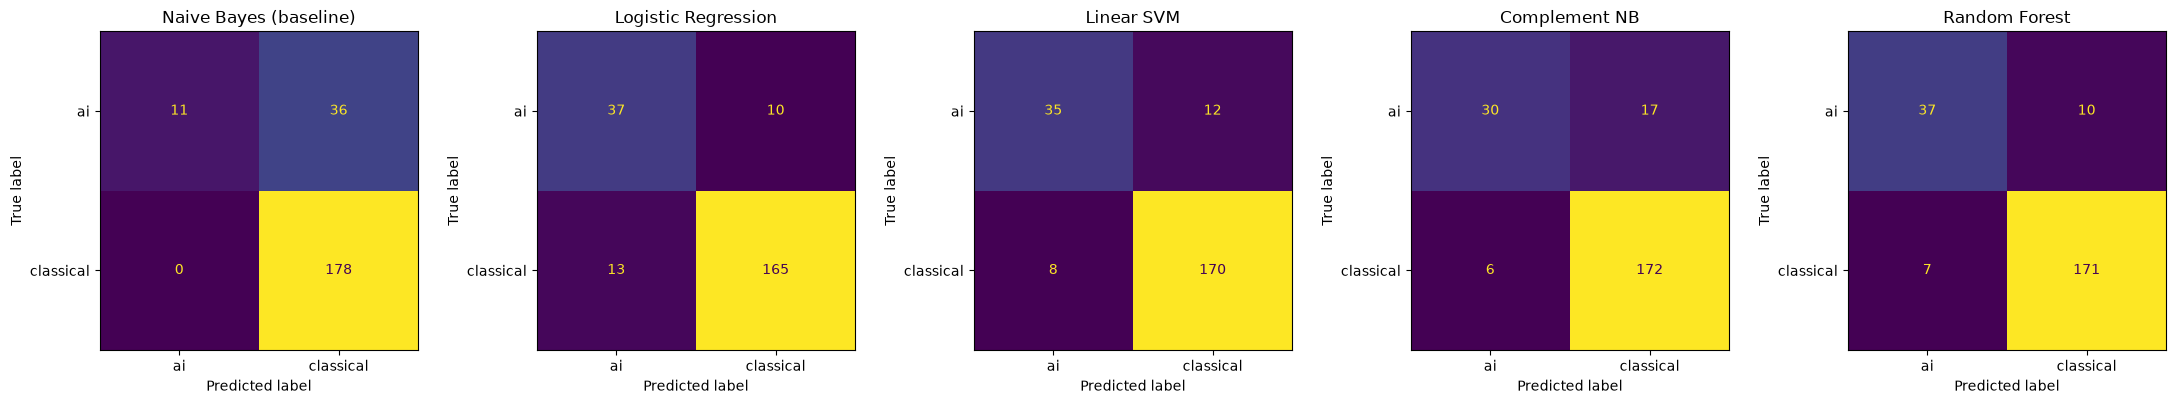

In [22]:
#confusion matrices for the models
fig, axes = plt.subplots(1, len(fitted_models), figsize=(22, 4))

for ax, (name, pipe) in zip(axes, fitted_models.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, pipe.predict(X_test), ax=ax, colorbar=False)
    ax.set_title(name)

plt.tight_layout()
plt.show()

----------
QUESTION 2.2

-------
Chosen enhancement: Class weighting
Chosen as the data is 79/21 imbalanced and the baseline only found 23% of AI abstracts

In [23]:
#class weighting, showing same models with and without class weighting
weight_test = {
    "Logistic Regression": lambda w: LogisticRegression(class_weight=w, max_iter=1000, random_state=42),
    "Linear SVM": lambda w: LinearSVC(class_weight=w, random_state=42),
    "Random Forest": lambda w: RandomForestClassifier(n_estimators=300, class_weight=w, random_state=42, n_jobs=-1)
}

weight_results = []
for name, make_model in weight_test.items():
    for w in [None, "balanced"]:
        pipe = Pipeline([
            ("tfidf", TfidfVectorizer(max_features=5000, ngram_range=(1,2), min_df=2)),
            ("model", make_model(w))
        ])
        cv = cross_val_score(pipe, X_train, y_train, cv=5, scoring="f1_macro")
        pipe.fit(X_train, y_train)
        pred = pipe.predict(X_test)
        weight_results.append({
        "Model": name, 
        "Class weighting": "balanced" if w else "none",
        "CV macro F1": cv.mean(),
        "Test macro F1": f1_score(y_test, pred, average="macro"),
        "Test AI recall": recall_score(y_test, pred, pos_label="ai")
        })

print(pd.DataFrame(weight_results).round(3).to_string(index=False))

              Model Class weighting  CV macro F1  Test macro F1  Test AI recall
Logistic Regression            none        0.690          0.628           0.213
Logistic Regression        balanced        0.820          0.849           0.787
         Linear SVM            none        0.844          0.866           0.681
         Linear SVM        balanced        0.832          0.861           0.745
      Random Forest            none        0.833          0.828           0.553
      Random Forest        balanced        0.849          0.883           0.787


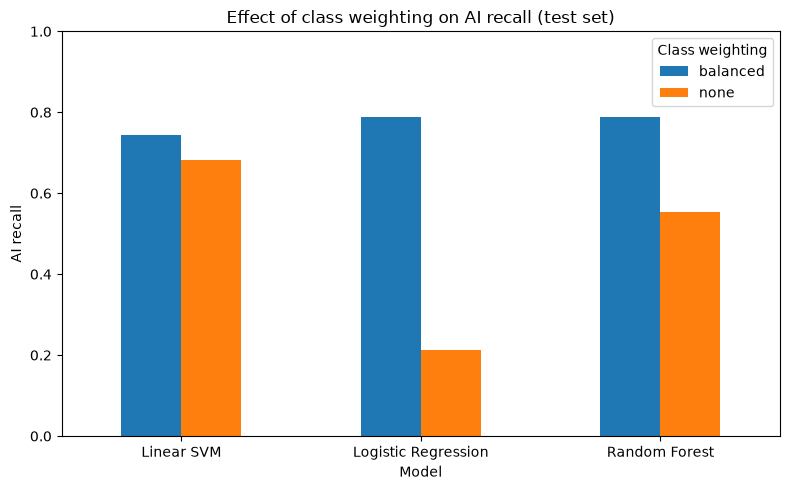

In [24]:
#AI recall with vs without class weighting for each model
weight_df = pd.DataFrame(weight_results)
weight_df.pivot(index="Model", columns="Class weighting", values="Test AI recall").plot(kind="bar", figsize=(8,5))
plt.title("Effect of class weighting on AI recall (test set)")
plt.ylabel("AI recall")
plt.ylim(0,1)
plt.xticks(rotation=0)
plt.legend(title="Class weighting")
plt.tight_layout()
plt.show()

---------
Class weighting clearly improved Logistic Regression (CV macro F1 0.690 to 0.820, and AI recall 0.213 to 0.787) and Random Forest (CV macro F1 0.833 to 0.849, and AI recall 0.553 to 0.787), fixing the bias towards the "classical" class send in the baseline. Linear SVM gained AI recall (0.681 to 0.745) but CV macro F1 dipped slightly, as SVMs depend less on class frequencies. The balanced Random Forest performed best overall and is deployed in Q2.3. Hyperparameter tuning, threshold adjustment and a voting ensemble were also tested but gave no meaningful further improvement.

------------
QUESTION 2.3

In [25]:
import joblib
import os

#best config from 2.2
final_model = fitted_models["Random Forest"]

#saving whole pipeline as one file
os.makedirs("../deployment", exist_ok=True)
joblib.dump(final_model, "../deployment/model.pkl")
print("model saved")

model saved
